# Does a 200-Day SMA Crossover Generate Alpha? A Fama-French Regression on SPY

This notebook tests whether a simple trend-following rule produces alpha once we account for known risk factors.

**The strategy:** hold SPY when its price closes above its 200-day simple moving average (SMA), and hold cash (earning the risk-free rate) otherwise.

**The test:** regress the strategy's monthly excess returns on the Fama-French three factors (market, size and value). If the intercept, alpha, is positive and statistically significant, the strategy earned returns the factors can't explain.

**Data:** daily SPY prices and monthly Fama-French factors from 2000 through 2023, downloaded with the `tidyfinance` package.

**Spoiler:** I don't expect a strategy this simple to generate alpha. The goal is to practice the full workflow: building the strategy without lookahead bias, running the regression with robust standard errors, and checking the regression assumptions.


In [13]:
import pandas as pd
import statsmodels.api as sm
import tidyfinance as tf
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
tf.set_backend("polars")

In [14]:
# Step 1: Download data

prices = tf.download_data(
    domain="Stock Prices",
    symbols="SPY",
    start_date="2000-01-01",
    end_date="2024-01-01"
)
factors_ff3_monthly = tf.download_data(
    domain="Fama-French",
    dataset="Fama/French 3 Factors",
    start_date="2000-10-01",
    end_date="2024-01-01",
)

## Step 2: Build the strategy

The transformation runs in five stages:

1. **SMA:** compute the 200-day moving average and shift it by one day, so each day's SMA uses only past prices.
2. **Returns:** compute SPY's daily percentage return.
3. **Signal:** the signal is 1 when the close is above the SMA, and 0 otherwise.
4. **Position:** shift the signal by one day, so we trade on the *next* day's return. Without this shift, we would be earning today's return using a signal based on today's close, which is lookahead bias.
5. **Monthly aggregation:** compound daily returns into monthly returns, and record `invested`, the fraction of days in each month the strategy held SPY.

Finally, we join the Fama-French factors and compute the excess return. On days in cash, the strategy earns the risk-free rate, which is zero *excess* return. So the monthly excess return is:

$$
\text{excess\_ret} = \text{ret} - \text{invested} \times R_f
$$


In [15]:
# Step 2: Transform data

sma_lag = (prices
    .sort("date", "symbol")
    .with_columns(sma=pl.col("adjusted_close").rolling_mean(window_size=200).shift(1).over("symbol"))
    .select("date", "sma", "symbol", "adjusted_close")
    .drop_nulls("sma")
)
returns = (sma_lag
    .sort("date", "symbol")
    .with_columns(ret=pl.col("adjusted_close").pct_change().over("symbol"))
    .select("date", "symbol", "ret", "sma", "adjusted_close")
    .drop_nulls("ret")
)
add_signal = (returns
    .sort("date", "symbol")
    .with_columns(signal=pl.when(pl.col("adjusted_close") > pl.col("sma")).then(1).otherwise(0))
    .select("date", "symbol", "ret", "sma", "signal")
)
final_returns = (add_signal
    .sort("date", "symbol")
    .with_columns(position=pl.col("signal").shift(1).over("symbol"))
    .with_columns(returns=pl.col("position") * pl.col("ret"))
    .drop_nulls("position")
    .select("date", "symbol", "returns", "position")
)
monthly_data = (final_returns
    .with_columns(date=pl.col("date").dt.truncate("1mo"))
    .group_by("date", "symbol")
    .agg(
        ret=(pl.col("returns") + 1).product() - 1,
        invested=pl.col("position").mean()
    )
    .sort("date", "symbol")
)
dataset = (monthly_data
    .join(factors_ff3_monthly, how="left", on="date")
    .with_columns(
        excess_ret=pl.col("ret") - pl.col("invested") * pl.col("risk_free")
    )
    .select("date", "symbol", "excess_ret", "mkt_excess", "hml", "smb", "invested")
)
dataset

date,symbol,excess_ret,mkt_excess,hml,smb,invested
date,str,f64,f64,f64,f64,f64
2000-10-01,"""SPY""",0.0,-0.0278,0.0564,-0.0383,0.0
2000-11-01,"""SPY""",0.0,-0.107,0.1225,-0.0307,0.0
2000-12-01,"""SPY""",0.0,0.0118,0.0754,0.0085,0.0
2001-01-01,"""SPY""",0.0,0.0325,-0.0506,0.0639,0.0
2001-02-01,"""SPY""",0.0,-0.1003,0.1222,-0.0064,0.0
…,…,…,…,…,…,…
2023-08-01,"""SPY""",-0.020752,-0.0236,-0.0115,-0.0313,1.0
2023-09-01,"""SPY""",-0.051734,-0.0523,0.015,-0.025,1.0
2023-10-01,"""SPY""",-0.027075,-0.0315,0.0022,-0.0387,0.818182


## Step 3: Run the regression

Now that the data is organized, we can run an ordinary least squares (OLS) multiple regression. Polars and statsmodels make this straightforward: we extract each column as a NumPy array, add a constant (the intercept), and fit the model.

- **Y:** the strategy's monthly excess return over the risk-free rate
- **X1:** the market excess return (Mkt-RF)
- **X2:** the Fama-French value factor, High Minus Low (HML)
- **X3:** the Fama-French size factor, Small Minus Big (SMB)

The model is:

$$
R_{p,t} - R_{f,t} = \alpha + \beta_{1}(R_{m,t} - R_{f,t}) + \beta_{2}\,HML_t + \beta_{3}\,SMB_t + \varepsilon_t
$$

Where:

- $R_{p,t} - R_{f,t}$: the strategy's excess return in month $t$
- $\alpha$: the intercept, or the strategy's alpha
- $R_{m,t} - R_{f,t}$: the market excess return
- $HML_t$, $SMB_t$: the value and size factors
- $\varepsilon_t$: the residual

If the strategy works, there will be a positive intercept left over that none of the factors explain. That leftover return is alpha.

### Why HAC standard errors?

When fitting the model, we set `cov_type="HAC"`. This doesn't change the coefficients at all. It only changes how their **standard errors** are calculated, which determines the t-statistics and p-values.

Standard OLS errors assume every month's error comes from the same distribution, with the same variance, independent of every other month. They estimate one number, the average squared residual, and apply it to every month. That assumption is a poor fit for financial data: markets alternate between calm and turbulent periods, and errors in nearby months can be related.

HAC (Heteroskedasticity and Autocorrelation Consistent) standard errors, also called Newey-West standard errors, drop both assumptions and use what the residuals actually show:

1. **Heteroskedasticity (H):** instead of one variance for all months, each month contributes its own squared residual, weighted by its factor values. Months with large residuals and large market moves get more weight, so turbulent months count for what they're worth.

2. **Autocorrelation (AC):** HAC also adds the products of residuals from nearby months, up to `maxlags=6`. If this month's error tends to have the same sign as next month's, the data contains less independent information than the sample size suggests, so the standard errors should be wider. More distant lags get smaller weights; Newey-West uses linearly declining weights, which keeps the estimate stable.

### Checking the regression assumptions

Before trusting the results, we check four assumptions:

- **Homoskedasticity:** is the variance of the residuals constant across fitted values? HAC standard errors make our inference valid even if this fails, but it's still worth seeing *why* it fails.
- **Independence:** are the residuals unrelated to one another over time?
- **Normality:** are the residuals approximately normally distributed?
- **Multicollinearity:** are the independent variables strongly correlated with one another?


In [16]:
# Y: strategy excess return; X: Mkt-RF, HML, SMB (in that order)
Y = dataset["excess_ret"].to_numpy()
X = np.column_stack([
    dataset["mkt_excess"].to_numpy(),
    dataset["hml"].to_numpy(),
    dataset["smb"].to_numpy()
])

X = sm.add_constant(X)

model = sm.OLS(Y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6}) # fit the OLS model with HAC (Newey-West) standard errors

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.406
Model:                            OLS   Adj. R-squared:                  0.399
Method:                 Least Squares   F-statistic:                     10.86
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           9.15e-07
Time:                        17:28:45   Log-Likelihood:                 658.51
No. Observations:                 279   AIC:                            -1309.
Df Residuals:                     275   BIC:                            -1294.
Df Model:                           3                                         
Covariance Type:                  HAC                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0026      0.001      1.840      0.066      -0.000       0.005
x1             0.4087      0.075      5.426      0.000       0.261       0.556
x2             0.0589      0.062      0.956      0.339      -0.062       0.180
x3            -0.0079      0.050     -0.159      0.873      -0.105       0.089
==============================================================================
Omnibus:                       12.450   Durbin-Watson:                   1.850
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               12.918
Skew:                          -0.479   Prob(JB):                      0.00157
Kurtosis:                       3.440   Cond. No.                         41.4
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity and autocorrelation robust (HAC) using 6 lags and without small sample correction
"""

### Interpreting the results

- **Alpha (const) = 0.0026,** about 0.26% per month or roughly 3.1% per year. However, z = 1.84 and p = 0.066, and the 95% confidence interval includes zero. **We cannot conclude that the strategy generates alpha** at the 5% significance level.
- **Market beta (x1) = 0.41,** highly significant (z = 5.4). The strategy behaves like holding about 41% of the market.
- **HML (x2) and SMB (x3)** are both insignificant. That's expected, since the strategy only ever holds SPY or cash, so it has no meaningful value or size tilt.
- **R² = 0.41.** The factors explain 41% of the strategy's monthly variance. Most of the remainder comes from the strategy switching between invested and cash, which a linear model can't capture well. The diagnostics below show this directly.


Text(0.5, 1.0, 'Residuals vs. Fitted Values')

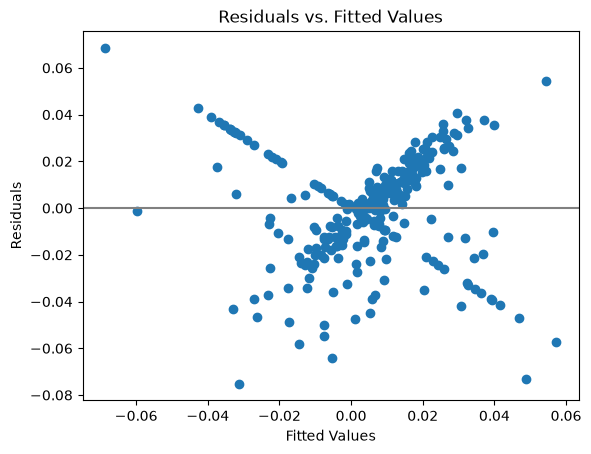

In [17]:
# Homoskedasticity: plot residuals against fitted values
plt.scatter(model.fittedvalues, model.resid)
plt.axhline(0, color="gray")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Values")

There is a clear **X-shaped pattern** in the residuals, so the residual variance is not constant. Why?

The strategy operates in two regimes: fully invested in SPY, or in cash earning the risk-free rate. The model, however, fits a single market beta of about 0.41 to both.

- **Invested months (the upward arm):** the strategy moves roughly one-for-one with the market, but the model only predicts 0.41 times the market. So in up months the residual is positive, and in down months it's negative.
- **Cash months (the downward arm):** the strategy's excess return is about zero, but the model still predicts 0.41 times the market. In down months, the model predicts a loss that didn't happen (positive residual); in up months, it predicts a gain the strategy missed (negative residual).

The residuals spread out as the fitted values get larger in either direction, which is exactly the heteroskedasticity that HAC standard errors correct for.


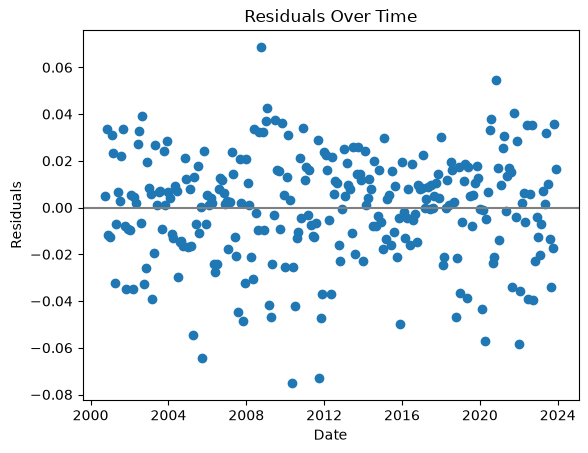

In [21]:
# Independence: plot residuals over time to look for any pattern
# or correlation between them
plt.scatter(dataset["date"], model.resid)
plt.title("Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.axhline(0, color="gray")

The residuals show no obvious pattern over time, and the Durbin-Watson statistic of 1.85 (close to 2) indicates little autocorrelation. The regression satisfies the independence assumption.

Text(0.5, 0, 'Residuals')

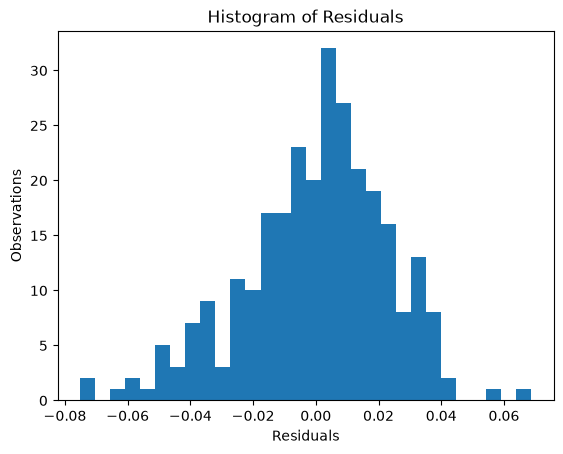

In [20]:
# Normality: histogram of the residuals
plt.hist(model.resid, bins=30)
plt.title("Histogram of Residuals")
plt.ylabel("Observations")
plt.xlabel("Residuals")

The residuals are approximately normal, but with some **negative skew** (skew = -0.48). The Jarque-Bera test (p = 0.002) confirms they aren't exactly normal. With 279 observations and HAC standard errors, this doesn't invalidate our inference, but the skew itself is informative.

A long left tail means occasional large losses the model doesn't explain, which would make most traders hesitant to put real capital behind this strategy. The negative skew appears for two reasons:

1. **Sudden crashes while still invested.** The 200-day SMA lags, so when prices drop quickly, the strategy is fully exposed for the first leg down. Its loss is close to the full market loss, while the model predicts only 0.41 times that, leaving a large negative residual.

2. **V-shaped rebounds missed while in cash.** Large downturns are often followed by sharp recoveries. A long lag means the strategy is still in cash when the market rebounds. The model predicts a 0.41 times gain that never arrives, leaving another negative residual.

These are the hardest problems in trend-following: sometimes you react too slowly, and sometimes the trend reverses before you can react.

There's an irony here. Trend-following on a single index often has *less* negative skew in its raw returns than buy-and-hold, because it avoids long, slow bear markets. The negative skew shows up in the residuals because a linear model handles the timing structure poorly. Choosing the right model is just as important as choosing the trading rule, especially when testing whether a strategy has an edge.

Let's look closer by adding the residuals to the DataFrame and inspecting the worst months.

In [45]:
# Add the residuals to the DataFrame
dataset = (dataset
    .with_columns(resid=pl.Series(model.resid))
)
# Display the months with the lowest residuals
dataset.bottom_k(10, by="resid").select("date", "resid", "mkt_excess", "invested")

date,resid,mkt_excess,invested
date,f64,f64,f64
2010-05-01,-0.07514,-0.079,0.75
2011-10-01,-0.073047,0.1133,0.095238
2005-10-01,-0.064298,-0.0204,0.47619
2022-01-01,-0.058185,-0.0616,0.8
2020-04-01,-0.057211,0.136,0.0
2005-04-01,-0.054693,-0.0261,0.809524
2015-12-01,-0.049912,-0.0215,0.681818
2007-11-01,-0.04862,-0.048,0.380952
2011-11-01,-0.047248,-0.0027,0.095238


This table shows when the strategy underperformed the model the most. The worst months fall into the two cases above:

- **Crash months while mostly invested,** such as May 2010 (the Flash Crash, 75% invested) and January 2022 (80% invested).
- **Rebounds missed while mostly in cash,** such as April 2020 and April 2009 (0% invested) and October 2011 (10% invested).

In both cases, the long lag of the 200-day SMA is the culprit.

### Multicollinearity

Now let's check the last assumption, multicollinearity. The standard test is the **Variance Inflation Factor (VIF)**, available in statsmodels as `variance_inflation_factor`.

For each factor, VIF regresses that factor on all the other factors and computes 1 / (1 - R²). For example, if the other factors explain 90% of a factor's variation, its VIF is 10, meaning its coefficient's variance is inflated tenfold compared with a regressor uncorrelated with the others.

A VIF near 1 means no multicollinearity. Values above 5 are worth noting, and values above 10 indicate a serious problem.


In [46]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Names must match the column order of X: const, Mkt-RF, HML, SMB
names = ["const", "mkt_excess", "hml", "smb"]
for i, name in enumerate(names):
    if name != "const":
        print(name, variance_inflation_factor(X, i))

mkt_excess 1.1108915438255407
hml 1.0003583840492314
smb 1.1111079897924272


All three VIFs are close to 1, so there is no multicollinearity in the model. That's expected, since the Fama-French factors were designed to be largely uncorrelated.

## Conclusion

After accounting for cash returns and using robust standard errors, **the 200-day SMA strategy on SPY shows no statistically significant alpha.** Its returns are mostly explained by holding about 41% of the market's exposure.

The diagnostics also show that a linear factor model is a poor fit for a strategy that switches between being fully invested and holding cash. Possible extensions:

- Add an interaction term, $(R_{m,t} - R_{f,t}) \times Invested_t$, to model the two regimes directly.
- Add a squared market term (the Treynor-Mazuy model) to test for market-timing ability.
- Add the momentum factor (UMD) to see whether the strategy loads on momentum.
- Test other SMA lengths, while correcting for multiple testing.

This process, from idea to data, model and diagnostics, is what any investor should do when developing a strategy. Rigorous statistical testing matters, especially when trading with capital that isn't your own.
